## Q1. Dataset Loading

Load the Diabetes Dataset using Scikit-learn and display the first 10 records, dataset shape, feature names, and target variable.

In [1]:

import pandas as pd
from sklearn.datasets import load_diabetes


diabetes = load_diabetes()


df = pd.DataFrame(
    diabetes.data,
    columns=diabetes.feature_names
)





In [2]:
df["target"] = diabetes.target




In [3]:

print(df.head(10))


        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   
5 -0.092695 -0.044642 -0.040696 -0.019442 -0.068991 -0.079288  0.041277   
6 -0.045472  0.050680 -0.047163 -0.015999 -0.040096 -0.024800  0.000779   
7  0.063504  0.050680 -0.001895  0.066629  0.090620  0.108914  0.022869   
8  0.041708  0.050680  0.061696 -0.040099 -0.013953  0.006202 -0.028674   
9 -0.070900 -0.044642  0.039062 -0.033213 -0.012577 -0.034508 -0.024993   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.0

In [4]:

print(df.shape)

(442, 11)


In [5]:

print(diabetes.feature_names)

['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


## Q2. Exploratory Data Analysis (EDA)

Perform Exploratory Data Analysis (EDA) by:

    Checking data types
    Identifying missing values
    Displaying statistical summary
    Finding duplicate records

In [8]:
df.dtypes

age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object

In [10]:
df.isna().sum()

age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

In [11]:
df.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


In [13]:
df.duplicated().sum()

np.int64(0)

## Q3. Data Visualization

Create the following visualizations:

    Histogram of the target variable
    Correlation Heatmap
    Scatter Plot between the most important feature and the target variable
    Box Plot to identify outliers
    Write your observations for each visualization.

**1 Histogram of the Target Variable**

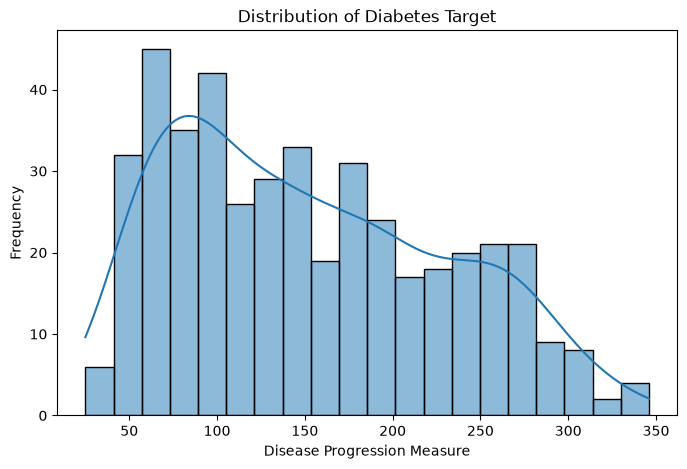

In [14]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(df["target"], bins=20, kde=True)

plt.title("Distribution of Diabetes Target")
plt.xlabel("Disease Progression Measure")
plt.ylabel("Frequency")

plt.show()


**Observation:** The histogram shows how the target values are distributed and whether the distribution is symmetric or skewed

**2 Correlation Heatmap**

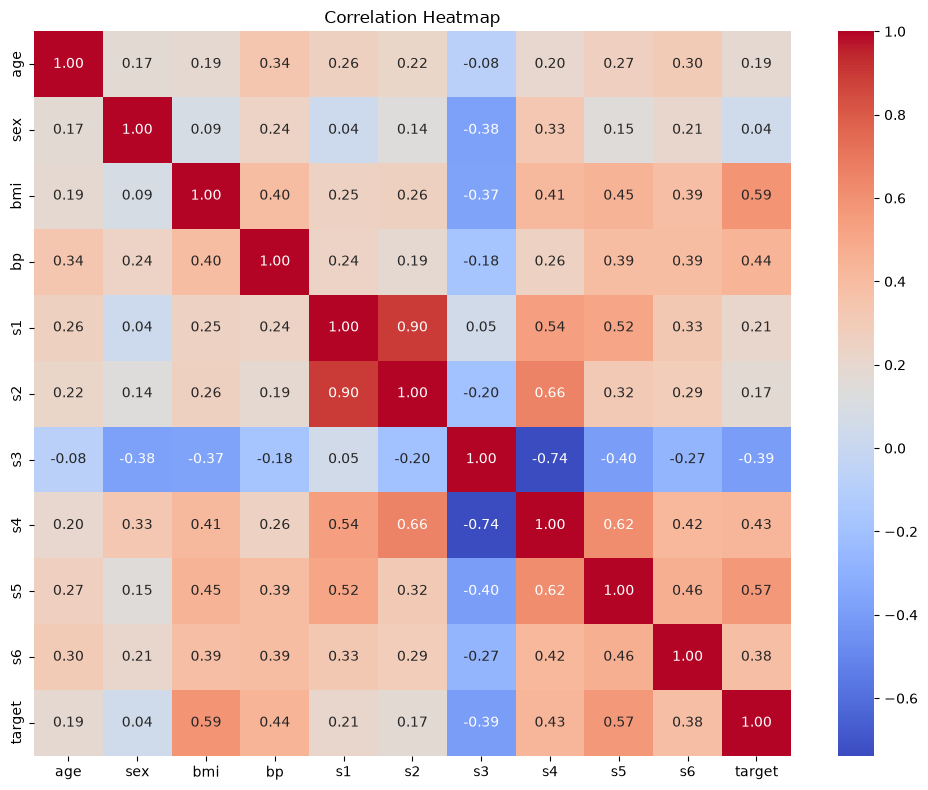

In [15]:

plt.figure(figsize=(10, 8))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


**Observations:**

Values close to +1 indicate a strong positive linear relationship.

Values close to -1 indicate a strong negative linear relationship.

Values close to 0 indicate a weak linear relationship.

**3 Scatter Plot Between the Most Important Feature and Target**

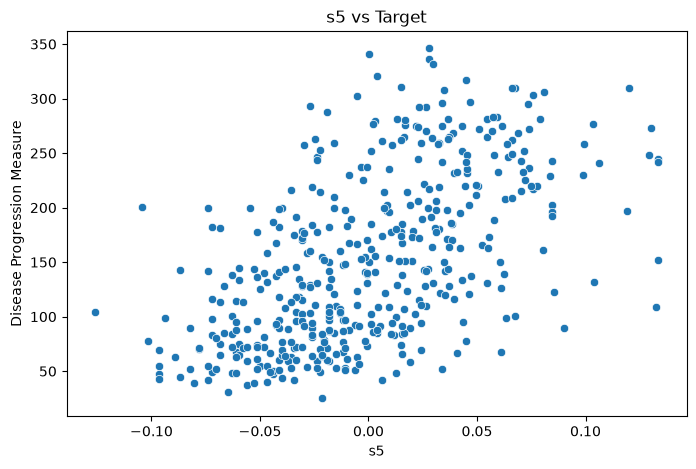

In [17]:

from sklearn.tree import DecisionTreeRegressor

X = df.drop(columns="target")
y = df["target"]
       
temp_model = DecisionTreeRegressor(random_state=42)
temp_model.fit(X, y)

importance = pd.Series(
    temp_model.feature_importances_,
    index=X.columns
)

top_feature = importance.idxmax()

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=df[top_feature],
    y=df["target"]
)

plt.title(f"{top_feature} vs Target")
plt.xlabel(top_feature)
plt.ylabel("Disease Progression Measure")

plt.show()


**Observation:** Points beyond the whiskers may indicate potential outliers. These values should be investigated rather than automatically removed.

**4 Box Plot to Identify Outliers**

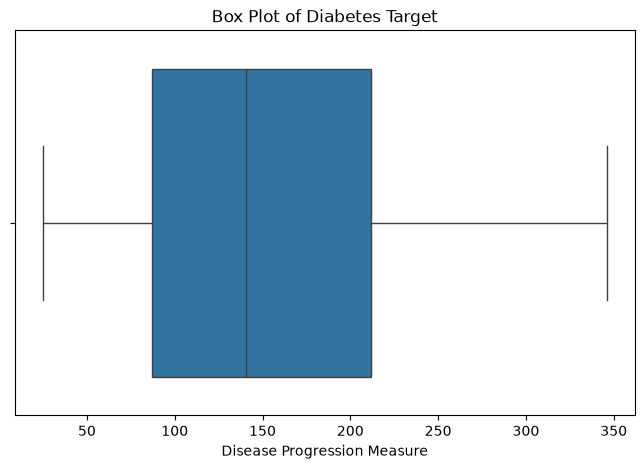

In [18]:

plt.figure(figsize=(8, 5))

sns.boxplot(x=df["target"])

plt.title("Box Plot of Diabetes Target")
plt.xlabel("Disease Progression Measure")

plt.show()


**Observation:** The training set is used to build the model, while the testing set evaluates its performance on unseen records. random_state=42 makes the split reproducible.

## Q4. Data Preprocessing

Prepare the dataset by:

    Separating features (X) and target (y)
    Splitting the data into 80% training and 20% testing sets using random_state=42
    Explain whether feature scaling is required for a Decision Tree Regressor.

In [20]:


from sklearn.model_selection import train_test_split

X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)



Training Features Shape: (353, 10)
Testing Features Shape: (89, 10)
Training Target Shape: (353,)
Testing Target Shape: (89,)


Feature scaling is generally not required for a Decision Tree Regressor because it makes predictions using feature-based splitting thresholds rather than distance calculations.

## Q5. Model Training

Build a Decision Tree Regressor using the training dataset and:

    Train the model
    Display the tree depth
    Display the number of leaf nodes
    Visualize the Decision Tree

In [21]:

model = DecisionTreeRegressor(random_state=42)

model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

In [22]:

print("Tree Depth:", model.get_depth())


Tree Depth: 19


In [23]:

print("Number of Leaf Nodes:", model.get_n_leaves())


Number of Leaf Nodes: 346


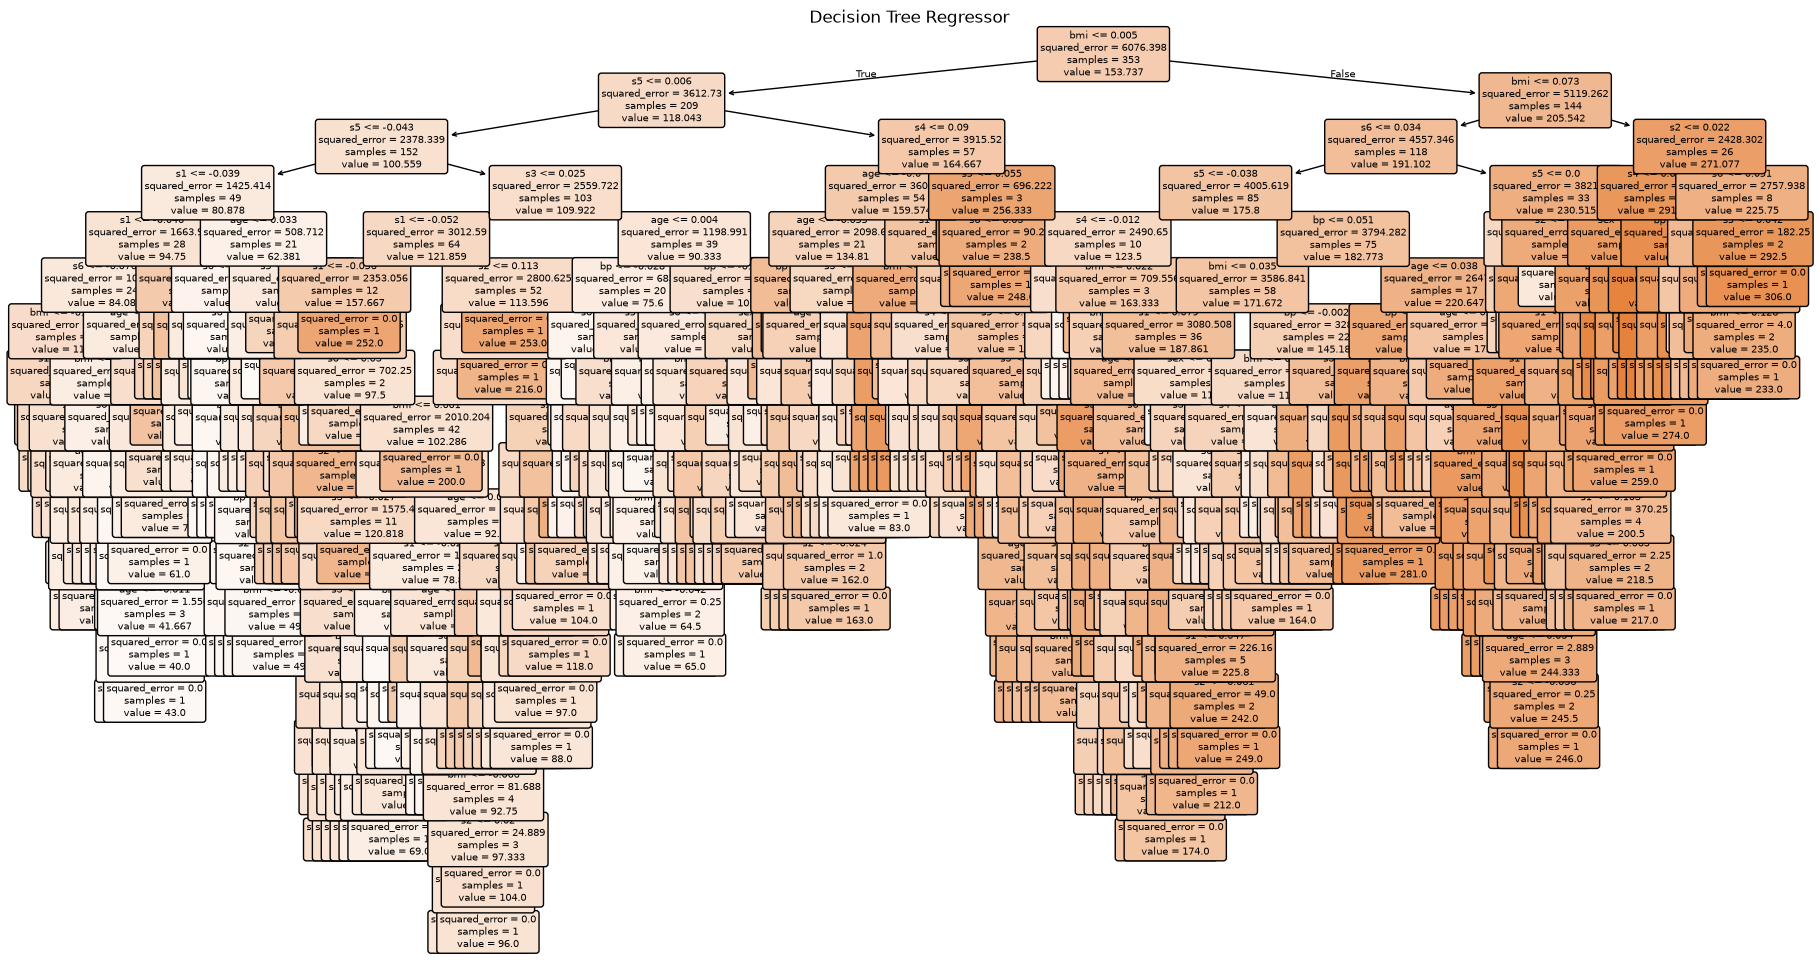

In [24]:

from sklearn.tree import plot_tree

plt.figure(figsize=(22, 12))

plot_tree(
    model,
    feature_names=diabetes.feature_names,
    filled=True,
    rounded=True,
    fontsize=7
)

plt.title("Decision Tree Regressor")
plt.show()


## Q6. Prediction

Predict the target values for the testing dataset and display a comparison of the Actual and Predicted values.

In [25]:

y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(comparison.to_string(index=False))


 Actual  Predicted
  219.0      206.0
   70.0       99.0
  202.0      170.0
  230.0      268.0
  111.0      183.0
   84.0       97.0
  242.0      233.0
  272.0      258.0
   94.0      206.0
   96.0      197.0
   94.0      113.0
  252.0      200.0
   99.0       74.0
  297.0      220.0
  135.0       86.0
   67.0      141.0
  295.0      310.0
  264.0      279.0
  170.0      293.0
  275.0      178.0
  310.0      147.0
   64.0       65.0
  128.0       47.0
  232.0      150.0
  129.0       85.0
  118.0      127.0
  263.0      281.0
   77.0      150.0
   48.0       59.0
  107.0      183.0
  140.0      128.0
  113.0       50.0
   90.0      276.0
  164.0      292.0
  180.0      164.0
  233.0      180.0
   42.0       53.0
   84.0       83.0
  172.0      120.0
   63.0       96.0
   48.0       39.0
  108.0       66.0
  156.0      199.0
  168.0      131.0
   90.0      170.0
   52.0       65.0
  200.0       59.0
   87.0      148.0
   90.0       39.0
  258.0      200.0
  136.0      141.0
  158.0     

## Q7. Model Evaluation

Evaluate the model using:

    Mean Absolute Error (MAE)
    Mean Squared Error (MSE)
    Root Mean Squared Error (RMSE)
    R² Score
    Interpret the results.

In [26]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np


mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


MAE: 54.52808988764045
MSE: 4976.797752808989
RMSE: 70.54642267903446
R2 Score: 0.060653981041140725


**Interpretation:**
- MAE: Represents the average absolute difference between actual and predicted values. A lower MAE indicates better predictions.
- MSE: Calculates the average squared prediction error. Larger errors receive greater penalties.
- RMSE: Represents the square root of MSE and expresses error in the same units as the target.
- R² Score: Measures the model's goodness of fit. A score closer to 1 generally indicates a better fit; a negative score means the model performs worse than predicting the test-set mean.

## Q8. Feature Importance

Display the feature importance scores and identify the top five most important features. Explain how these features influence the prediction.

Feature  Importance
    bmi    0.418232
     s5    0.155795
     s1    0.083177
    age    0.064586
     s3    0.063936
     bp    0.062494
     s6    0.061930
     s2    0.053389
     s4    0.029788
    sex    0.006673
Feature  Importance
    bmi    0.418232
     s5    0.155795
     s1    0.083177
    age    0.064586
     s3    0.063936


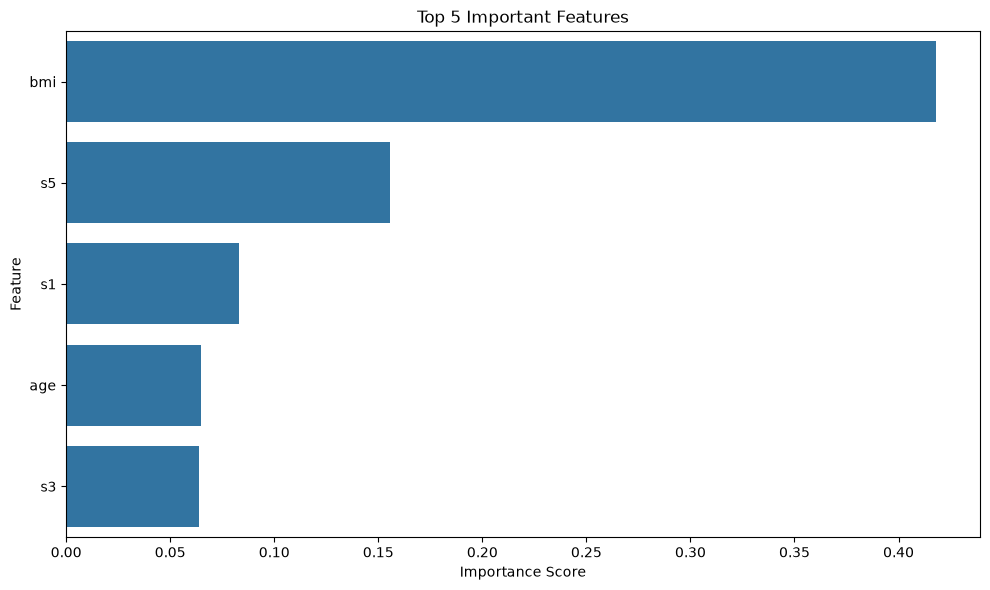

In [27]:

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.to_string(index=False))

print(importance_df.head(5).to_string(index=False))


plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(5),
    x="Importance",
    y="Feature"
)

plt.title("Top 5 Important Features")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


**Explanation:**  Feature importance measures the relative contribution of each feature to the Decision Tree Regressor's splitting decisions. The features are sorted in descending order to identify the top five.

## Q9. Hyperparameter Tuning

Train another Decision Tree Regressor by changing parameters such as:

    max_depth
    min_samples_split
    min_samples_leaf
    Compare the performance of both models and discuss the results.

In [28]:


from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

original_model = DecisionTreeRegressor(random_state=42)
original_model.fit(X_train, y_train)

original_pred = original_model.predict(X_test)


tuned_model = DecisionTreeRegressor(
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

tuned_model.fit(X_train, y_train)

tuned_pred = tuned_model.predict(X_test)


results = pd.DataFrame({
    "Model": ["Original Model", "Tuned Model"],
    "MAE": [
        mean_absolute_error(y_test, original_pred),
        mean_absolute_error(y_test, tuned_pred)
    ],
    "MSE": [
        mean_squared_error(y_test, original_pred),
        mean_squared_error(y_test, tuned_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, original_pred)),
        np.sqrt(mean_squared_error(y_test, tuned_pred))
    ],
    "R2 Score": [
        r2_score(y_test, original_pred),
        r2_score(y_test, tuned_pred)
    ]
})

print("Model Performance Comparison:")
print(results.to_string(index=False))


Model Performance Comparison:
         Model       MAE         MSE      RMSE  R2 Score
Original Model 54.528090 4976.797753 70.546423  0.060654
   Tuned Model 43.441655 2997.896425 54.753049  0.434162


## Q10. Conclusion

Write a short report that includes:

    Overall model performance
    Advantages and limitations of Decision Tree Regression
    Overfitting analysis
    Two real-world applications of Decision Tree Regression

## Conclusion: Decision Tree Regression

**1. Overall Model Performance**

The Decision Tree Regressor was trained using the Scikit-learn Diabetes dataset to predict a quantitative measure of disease progression. The model was evaluated using MAE, MSE, RMSE, and R² score. These metrics help measure prediction errors and assess model performance.

**2. Advantages of Decision Tree Regression**

- Easy to understand and interpret.
- Can capture nonlinear relationships between features and the target.
- Generally does not require feature scaling.
- Can be used for numerical prediction tasks.

**3. Limitations of Decision Tree Regression**

- Can overfit the training data.
- Small changes in the dataset can produce a different tree.
- A complex tree may perform poorly on unseen data.
- Predictions can be less accurate than those of other models on some datasets.

**4. Overfitting Analysis**

Overfitting occurs when a model learns the training data too closely and does not generalize well to unseen data. Limiting tree depth and increasing the minimum number of samples required for splitting and leaf nodes can help control overfitting. Comparing training and testing performance helps assess generalization.

**5. Real-World Applications**

- **Healthcare:** Predicting numerical health indicators or disease progression measurements using relevant patient data.
- **Real estate:** Predicting property prices based on features such as location, area, and number of rooms.

**Final Conclusion**

The Decision Tree Regressor is a useful machine learning algorithm for predicting continuous numerical values. Hyperparameter tuning can help control model complexity and reduce overfitting. The final model should be selected based on its performance on unseen testing data.